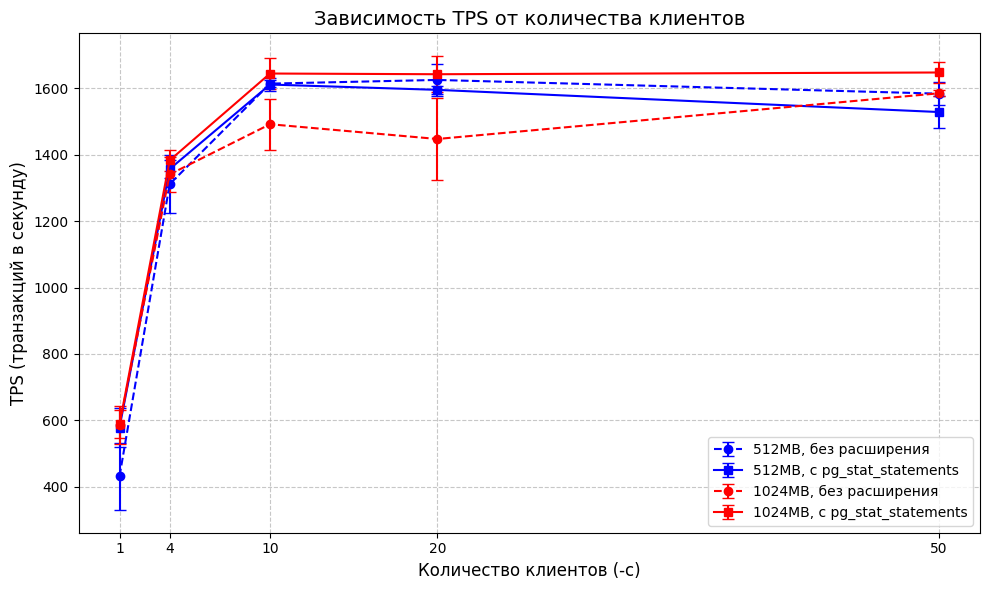

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Читаем CSV
df = pd.read_csv("ext_compare.csv")

# Группируем по buffers, extension, clients и считаем среднее TPS
g = df.groupby(["buffers", "extension", "clients"]).agg(
    tps_mean=("tps", "mean"),
    tps_std=("tps", "std")
).reset_index()

# Настройки стиля
plt.figure(figsize=(10, 6))

# Стили для 4 кривых
styles = {
    ("512MB", "off"): {"color": "blue", "marker": "o", "linestyle": "--", "label": "512MB, без расширения"},
    ("512MB", "on"):  {"color": "blue", "marker": "s", "linestyle": "-",  "label": "512MB, с pg_stat_statements"},
    ("1024MB", "off"):{"color": "red",  "marker": "o", "linestyle": "--", "label": "1024MB, без расширения"},
    ("1024MB", "on"): {"color": "red",  "marker": "s", "linestyle": "-",  "label": "1024MB, с pg_stat_statements"}
}

# Рисуем линии
for (buf, ext), style in styles.items():
    subset = g[(g["buffers"] == buf) & (g["extension"] == ext)].sort_values("clients")
    plt.errorbar(
        subset["clients"], subset["tps_mean"], yerr=subset["tps_std"],
        color=style["color"], marker=style["marker"], linestyle=style["linestyle"],
        capsize=4, label=style["label"]
    )

# Оформление
plt.title("Зависимость TPS от количества клиентов", fontsize=14)
plt.xlabel("Количество клиентов (-c)", fontsize=12)
plt.ylabel("TPS (транзакций в секунду)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.xticks([1, 4, 10, 20, 50]) # фиксируем точки по оси X
plt.tight_layout()

# Сохраняем и показываем
plt.savefig("tps_4_curves.png", dpi=150)
plt.show()